# Otorgamiento de Crédito Alemán

## 1. Introducción.

El otorgamiento de credito es un proceso crítico en la banca y las instituciones financieras, donde se evalua la probabilidad de que un solicitante incumpla con sus obligaciones de pago. Una adecuada gestión del riesgo permite minimizar pérdidas y optimizar la cartera crediticia. En este proyecto se aborda el problema utilizando el conjunto de datos **Statlog (German Credit Data)** del UCI del ML Repository, que contiene información del 1000 solicitudes de crédito junto a una descripción si un cliente es *buen* o *mal* pagador.

El proceso de otorgamiento de crédito cuenta con las siguientes fases:


1. Prospección y solicitud: Recopilación de datos personales, financieros y demográficos del solicitante (edad, estado civil, empleo, etc.).

2. Evaluación de riesgo (credit scoring): Análisis de la capacidad de pago y el historial crediticio. Se consideran variables como el saldo en cuenta corriente, créditos previos y estabilidad laboral.

3. Verificación y análisis de garantías: Evaluación de activos que respaldan la deuda (bienes raíces, ahorros, etc.).

3. Decisión de crédito: Con base en el perfil de riesgo, se aprueba o rechaza la solicitud. En este punto es fundamental considerar la matriz de costos proporcionada con el dataset, que penaliza cinco veces más clasificar a un mal pagador como bueno que viceversa.

4. Seguimiento y recuperación: Una vez otorgado el crédito, se monitorea su comportamiento para asegurar el retorno.

## 2. Planteamiento del Problema

El objetivo es desarrollar un modelo predictivo capaz de clasificar a los solicitantes de crédito en dos categorías: "Good" (Buen pagador) o "Bad" (Mal pagador). El desafío principal radica en la asimetría del riesgo financiero: clasificar erróneamente a un cliente "malo" como "bueno" es cinco veces más costoso para la institución que clasificar a un cliente "bueno" como "malo". Por lo tanto, no basta con maximizar la precisión global, sino que es necesario minimizar el costo total derivado de los errores de clasificación, utilizando la matriz de costos proporcionada más adelante.

### 2.1 Descripción del Dataset

El conjunto de datos Statlog (German Credit Data) fue aportado por el Prof. Dr. Hans Hofmann de la Universidad de Hamburgo y está disponible en el UCI Machine Learning Repository. Consta de 1000 instancias, cada una representando a un solicitante de crédito, con 20 atributos (7 numéricos y 13 categóricos) y una variable objetivo binaria.

### 2.2 Matriz de Costos

La evaluación de desempeño debe de considerar la siguiente matriz de costos, donde las filas representan la clase real y las columnas la clase predicha:


|          |Predicho: Bueno |Predicho: Malo|
:---------:|:--------------:|:------------:|
Real: Bueno| 0| 1|
Real: Malo|5|0|





In [ ]:
# @title
!pip install ucimlrepo

In [ ]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# fetch dataset
statlog_german_credit_data = fetch_ucirepo(id=144)

# data (as pandas dataframes)
X = statlog_german_credit_data.data.features
y = statlog_german_credit_data.data.targets

In [ ]:
statlog_german_credit_data.variables[['name', 'demographic','description', 'units']]

,name,demographic,description,units
0,Attribute1,None,Status of existing checking account,None
1,Attribute2,None,Duration,months
2,Attribute3,None,Credit history,None
3,Attribute4,None,Purpose,None
4,Attribute5,None,Credit amount,None
5,Attribute6,None,Savings account/bonds,None
6,Attribute7,Other,Present employment since,None
7,Attribute8,None,Installment rate in percentage of disposable i...,None
8,Attribute9,Marital Status,Personal status and sex,None
9,Attribute10,None,Other debtors / guarantors,None


In [ ]:
X.sample(3)

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
188,A11,12,A32,A43,674,A62,A74,4,A94,A101,1,A122,20,A143,A152,1,A173,1,A191,A201
180,A14,36,A33,A49,9572,A61,A72,1,A91,A101,1,A123,28,A143,A152,2,A173,1,A191,A201
71,A14,7,A34,A43,730,A65,A75,4,A93,A101,2,A122,46,A143,A151,2,A172,1,A192,A201


In [ ]:
y.value_counts()

,count
class,
1,700
2,300


Hay un notable desbalance entre las dos clases del target

## 3. Desarrollo

### 3.1 Preprocesamiento de datos



#### 3.1.1 Configuraciones

In [ ]:
import warnings
warnings.filterwarnings('ignore')
from numpy.random import seed
from sklearn.compose import ColumnTransformer

from src.configs import ATTRIBUTE_NAMES, SEED, build_cat_preprocessor

seed(SEED)

In [ ]:
# @title
cat_attributes = X.select_dtypes(include=['object']).columns.tolist()
num_attributes = X.select_dtypes(exclude=['object']).columns.tolist()


# num_transformer = build_num_preprocessor(num_attributes)
# por el momento, solo procesamosamos las datos categoricos como ordinales
eda_transformer = build_cat_preprocessor(ordinal_attributes=cat_attributes)
transformer_1 = ColumnTransformer(
    transformers = [
        cat_transformer[0]
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)


X_eda = eda_transfomer.fit_transform(X)
X_eda = pd.DataFrame(X_eda, columns=eda_transfomer.get_feature_names_out())

In [ ]:
X_eda = transformer_1.fit_transform(X)
X_eda = pd.DataFrame(X_eda, columns=transformer_1.get_feature_names_out())

### 3.2 EDA (Análisis Exploratorio de datos)

In [ ]:
import matplotlib.pyplot as plt 
import seaborn as sns 

from src.eda_utils import (
    setup_plot_style, 
    analyze_numerical,
    analyze_categorical
)

target_names = {1:'Good', 2: 'Bad'}

X_eda = X_eda.rename(columns=ATTRIBUTE_NAMES)

X_eda['class'] = y.replace(target_names)

setup_plot_style()

#### 3.2.1 Estadísticas Descriptivas

ESTADÍSTICAS DESCRIPTIVAS POR CLASE

DURATION_MONTHS:
        mean    std  min   25%   50%   75%   max
class                                           
Bad    24.86  13.28  6.0  12.0  24.0  36.0  72.0
Good   19.21  11.08  4.0  12.0  18.0  24.0  60.0
--------------------------------------------------------------------------------

CREDIT_AMOUNT:
          mean      std    min     25%     50%      75%      max
class                                                           
Bad    3938.13  3535.82  433.0  1352.5  2574.5  5141.50  18424.0
Good   2985.46  2401.47  250.0  1375.5  2244.0  3634.75  15857.0
--------------------------------------------------------------------------------

INSTALLMENT_RATE:
       mean   std  min  25%  50%  75%  max
class                                     
Bad    3.10  1.09  1.0  2.0  4.0  4.0  4.0
Good   2.92  1.13  1.0  2.0  3.0  4.0  4.0
--------------------------------------------------------------------------------

PRESENT_RESIDENCE_SINCE:
       mean   

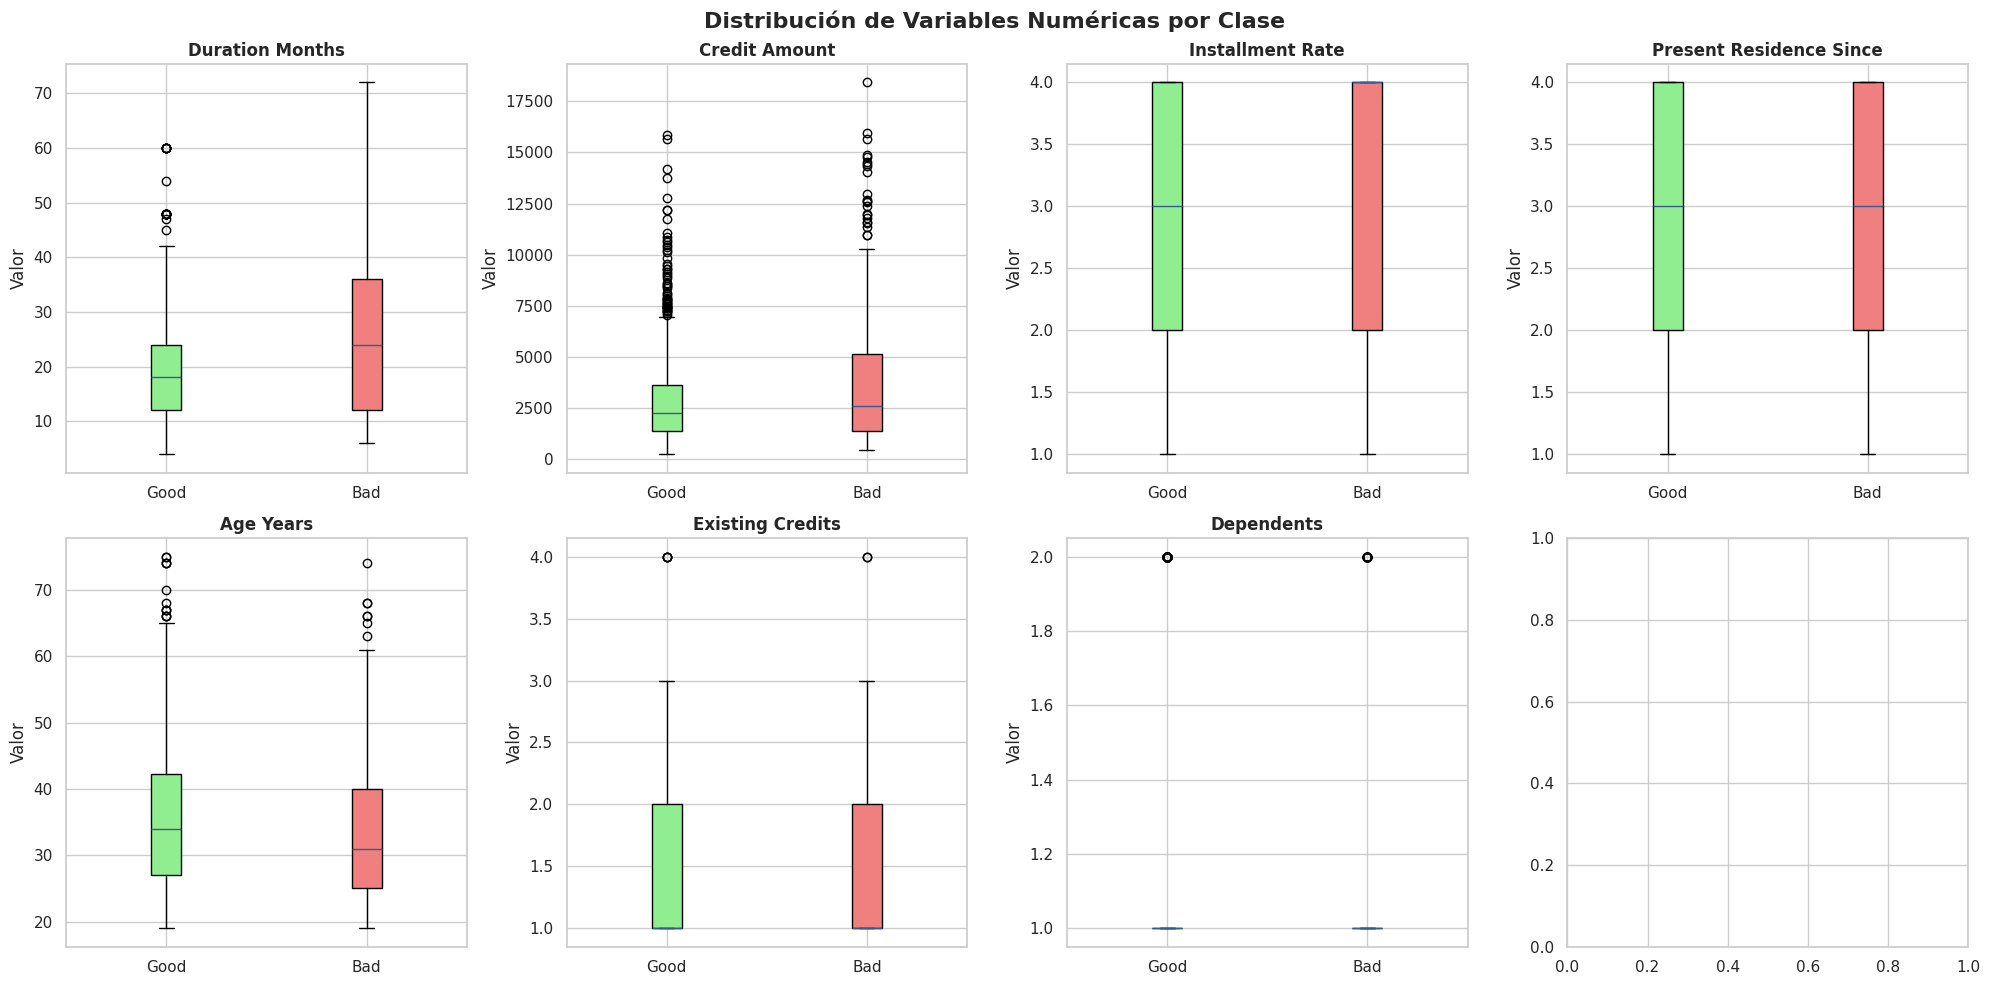

In [ ]:
print("ESTADÍSTICAS DESCRIPTIVAS POR CLASE")
print("="*60)

analyze_numerical(X_eda, num_attributes, target = 'class')

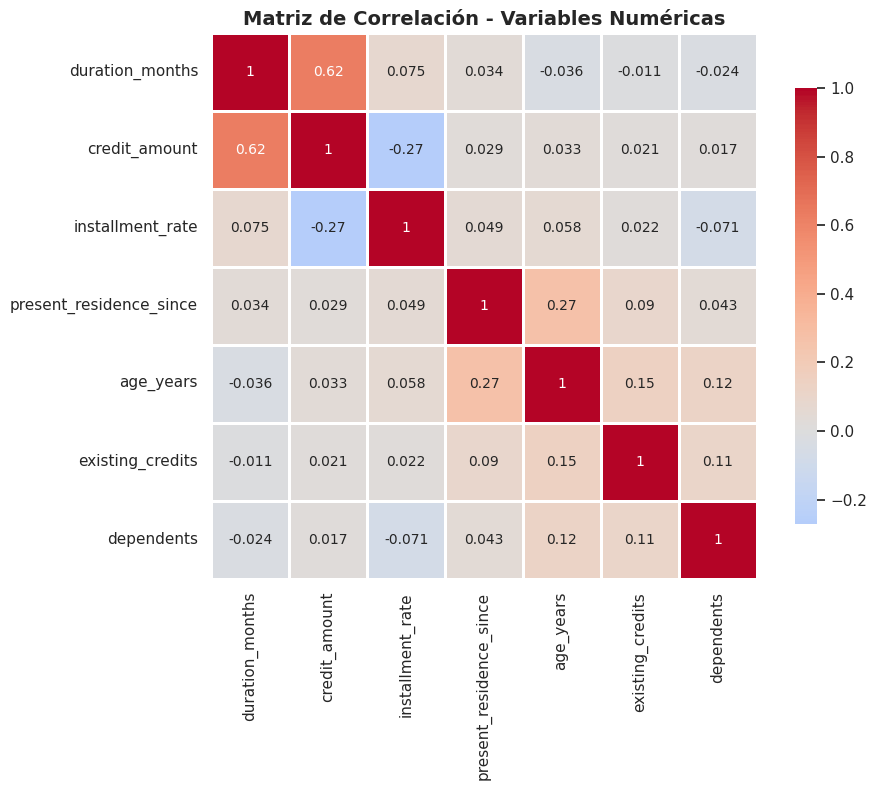

In [ ]:
corr_matrix = X_eda[[ATTRIBUTE_NAMES[att] for att in num_attributes]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Matriz de Correlación - Variables Numéricas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
X_eda.dependents.value_counts()

,count
dependents,
1.0,845
2.0,155


> Notamos que la mayoria de clientes son responsables de dar manutención a una sola persona (un 84% de clientes). Por lo tanto, se descartará este atributo para la construcción de los modelos.

#### 3.1.2 Análisis Variables Categóricas

ANÁLISIS DE VARIABLES CATEGÓRICAS CLAVE

------------------------------------------------------------
>	CHECKING_STATUS



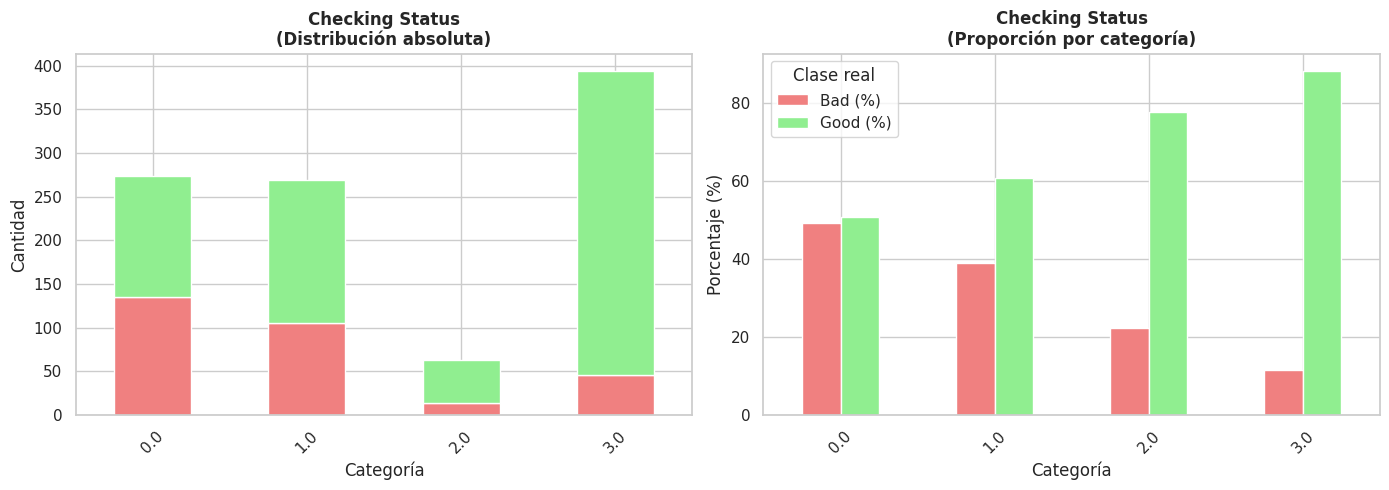


------------------------------------------------------------
>	CREDIT_HISTORY



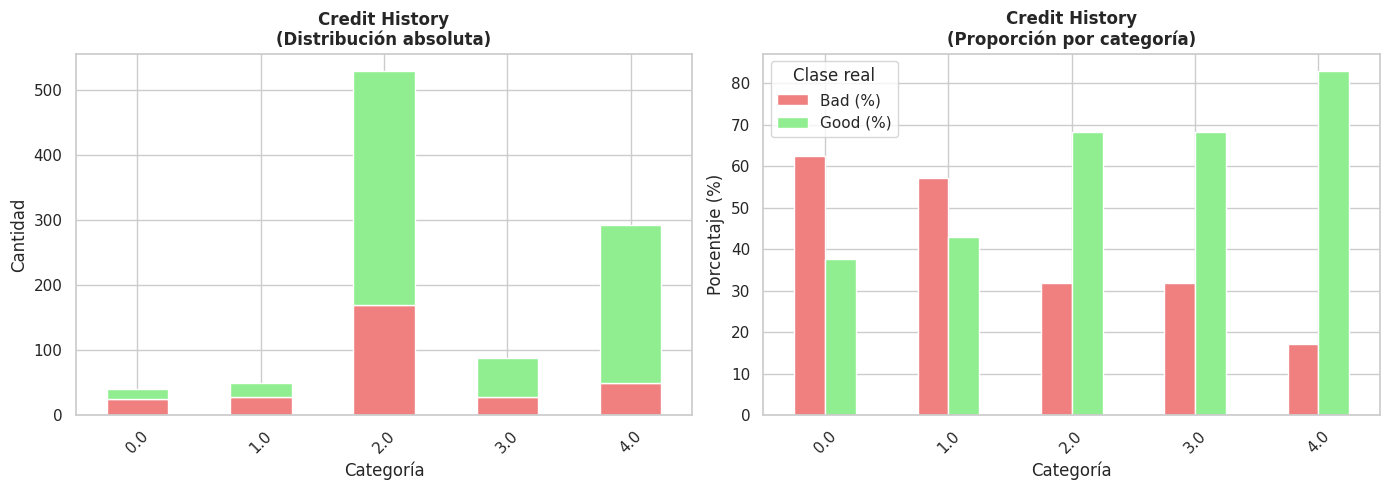


------------------------------------------------------------
>	PURPOSE



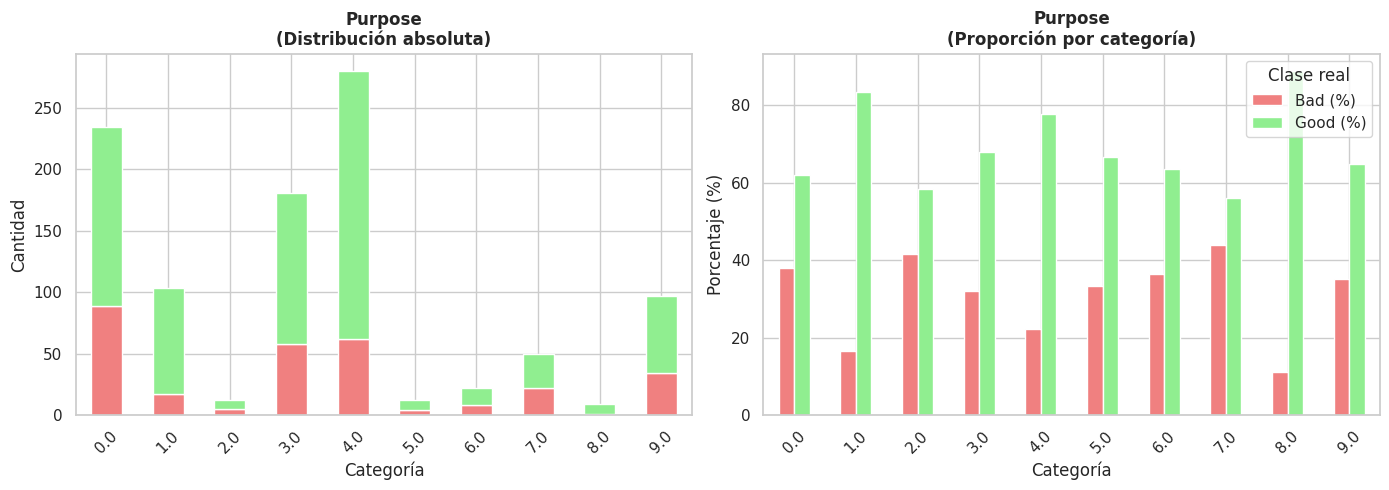


------------------------------------------------------------
>	SAVINGS_STATUS



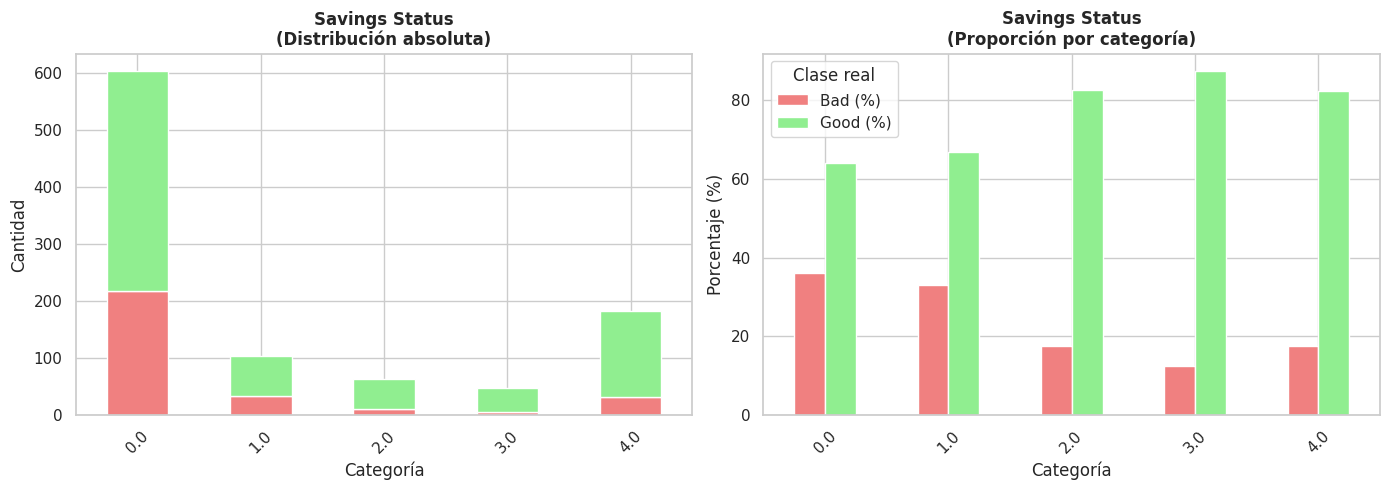


------------------------------------------------------------
>	EMPLOYMENT_DURATION



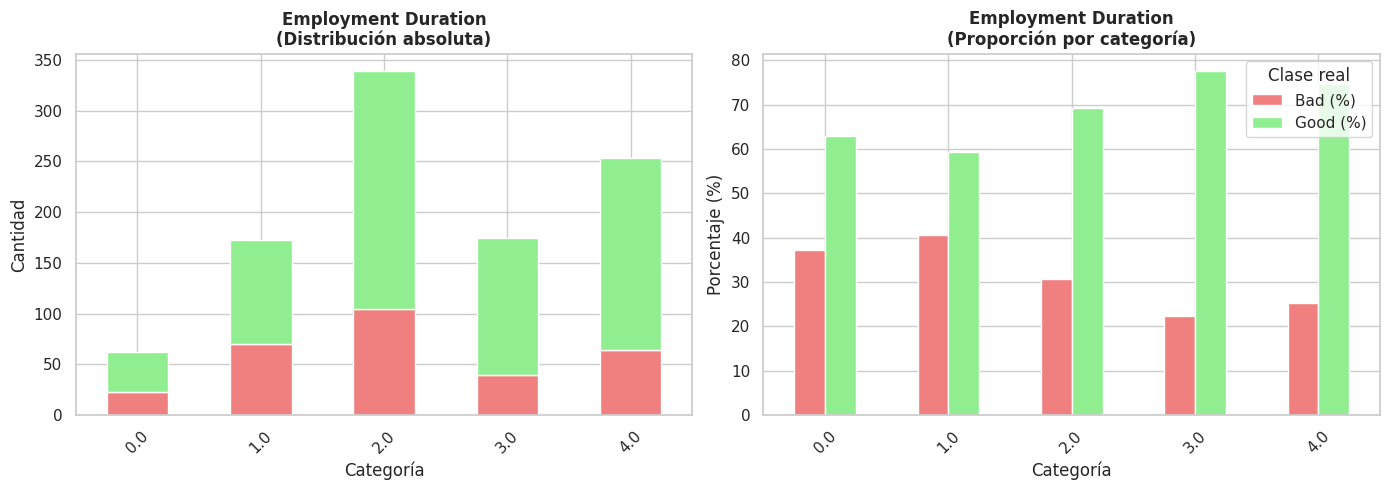


------------------------------------------------------------
>	PERSONAL_STATUS_SEX



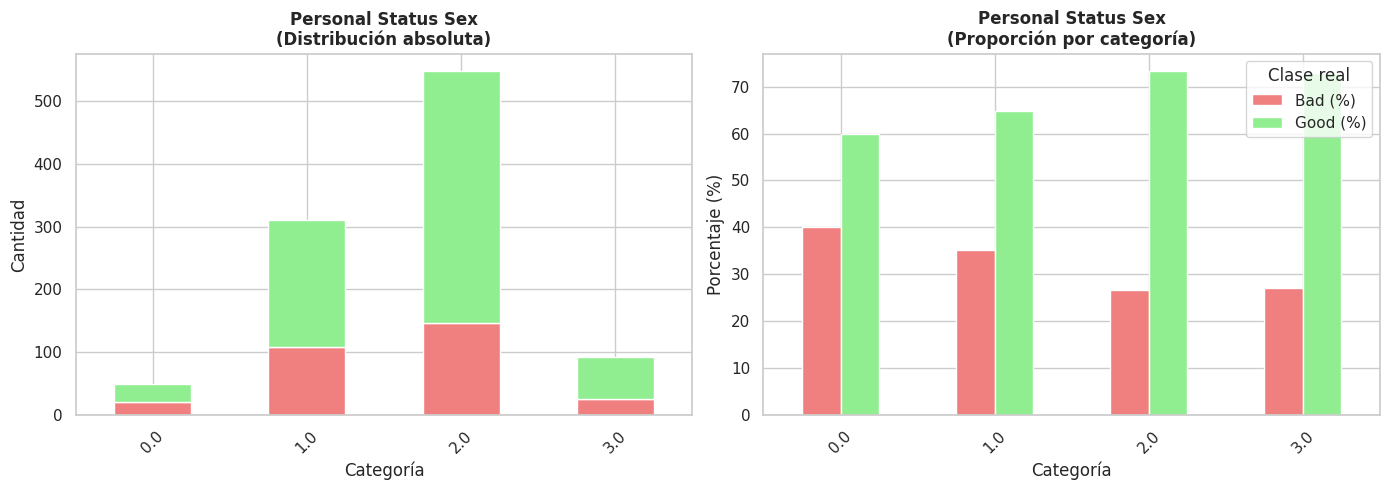


------------------------------------------------------------
>	OTHER_DEBTORS



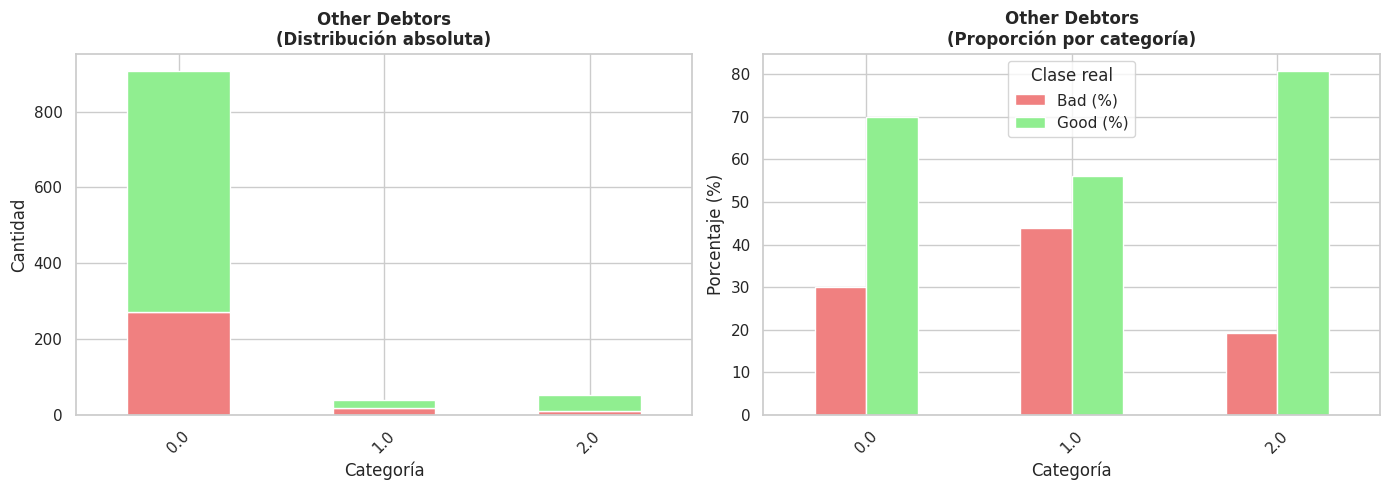


------------------------------------------------------------
>	PROPERTY



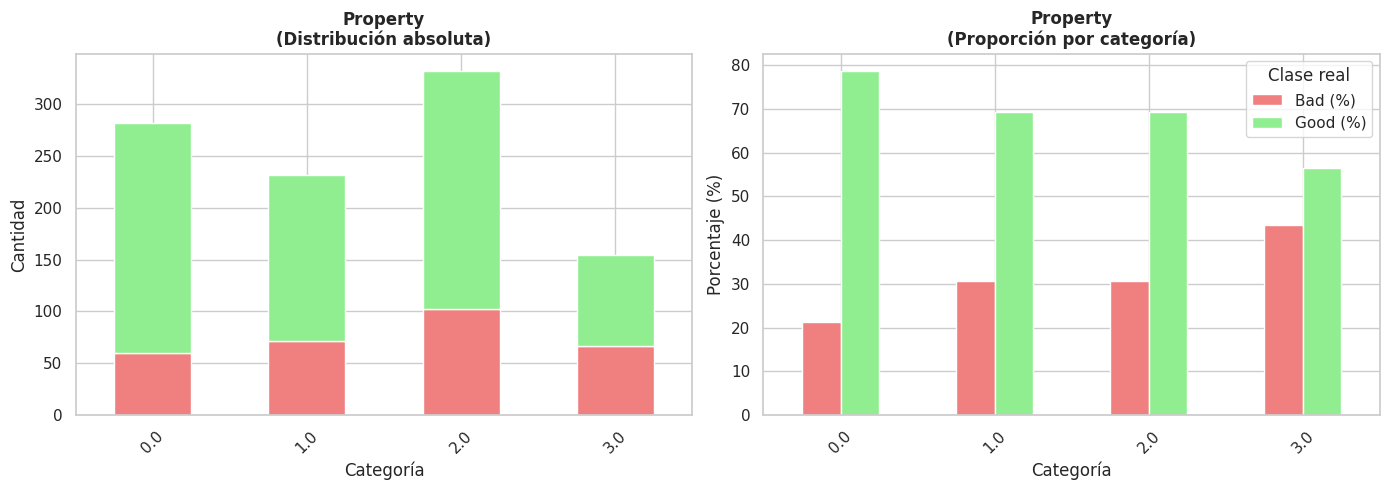


------------------------------------------------------------
>	OTHER_INSTALLMENT_PLANS



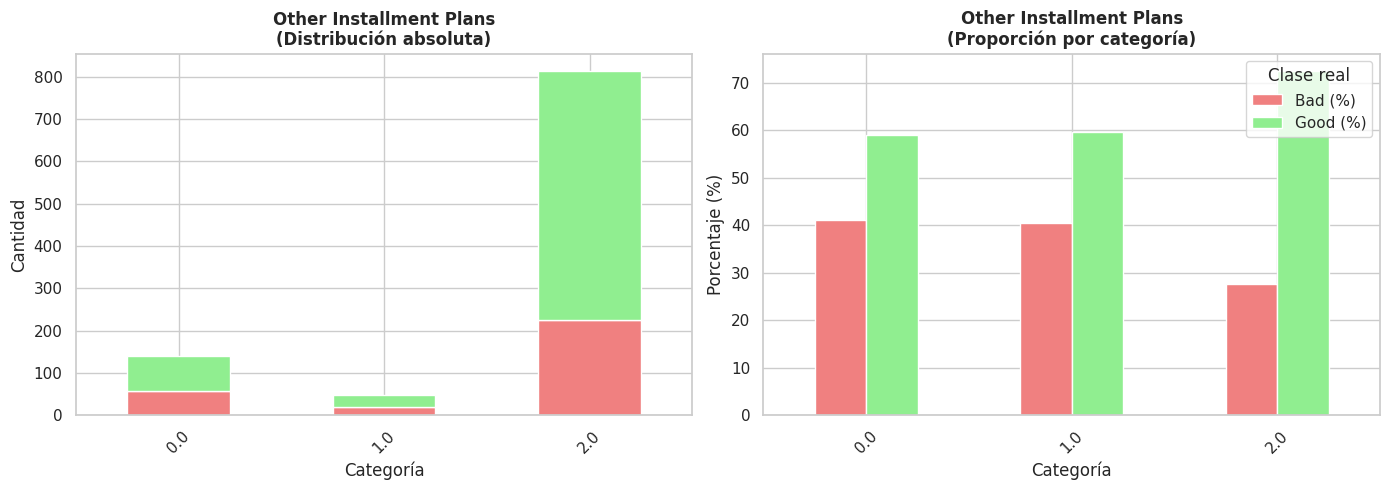


------------------------------------------------------------
>	HOUSING



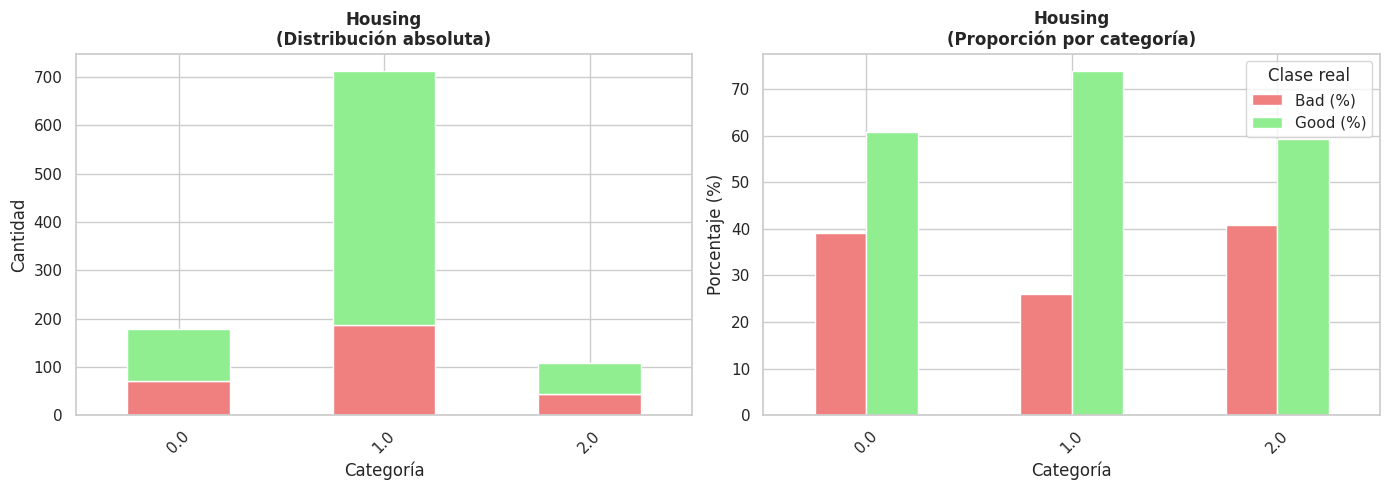


------------------------------------------------------------
>	JOB



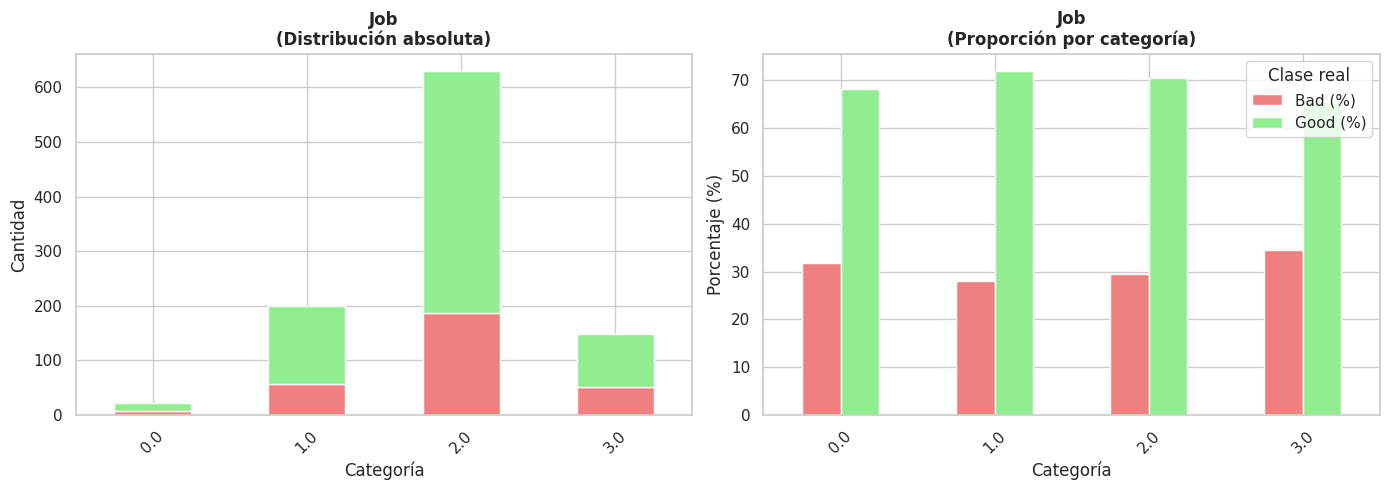


------------------------------------------------------------
>	TELEPHONE



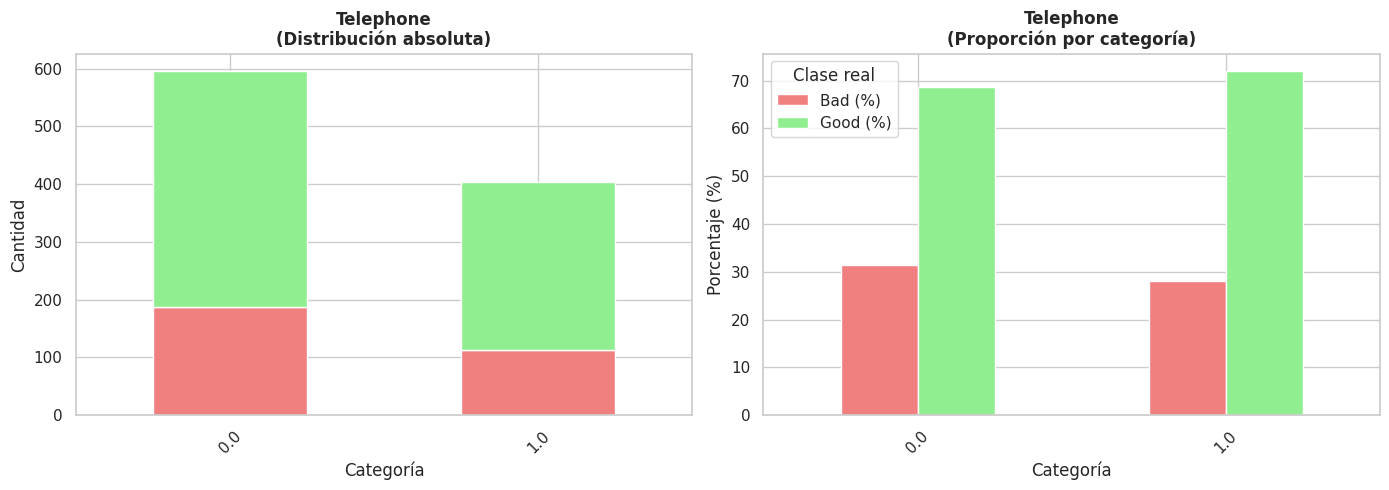


------------------------------------------------------------
>	FOREIGN_WORKER



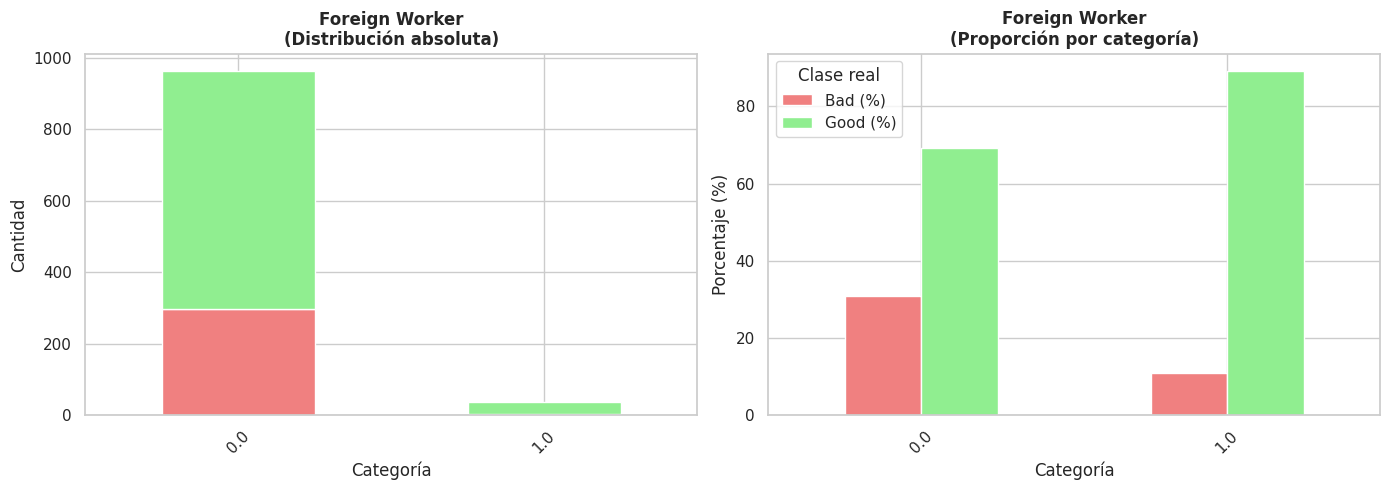

In [ ]:
print("="*60)
print("ANÁLISIS DE VARIABLES CATEGÓRICAS CLAVE")
print("="*60)

bad_rates_dict = {}
key_categoricals = [ATTRIBUTE_NAMES[cat_att] for  cat_att in cat_attributes]

for cat in key_categoricals:
    print("\n" + '-'*60 + "\n>" + f"\t{cat.upper()}\n" )
    bad_rates = analyze_categorical(X_eda, cat, target_col='class')
    bad_rates_dict[cat] = bad_rates

> De acuerdo a las gráficas anteriores, los atributos que no aportan información relevante para el otorgamiento de crédito, o bien, falta más información para que pueda ser considaro en los modelos.
> - Atributo 10: Otros deudores/Avaladores
> - Atributo 14: Otros planes de pago
> - Atributo 19: Telefono
> - Atributo 20: Trabajador Extranjero

In [ ]:
print("ANÁLISIS DE COSTOS")
print("="*60)

# Si aprobáramos todos los créditos
costo_todos = (X_eda['class'] == 'Bad').sum() * 5
print(f"Costo si aprobamos todos: {costo_todos}")

# Si rechazáramos todos
costo_ninguno = (X_eda['class'] == 'Good').sum() * 1
print(f"Costo si rechazamos todos: {costo_ninguno}")


ANÁLISIS DE COSTOS
Costo si aprobamos todos: 1500
Costo si rechazamos todos: 700


> Incluso con el 30% de clientes categorizados como malos, en caso de otorgarle el crédito a todos, esto presenta una pérdida significante.


### 3.3 Modelos no supervisados

El objetivo de esta tarea es poder segmentar a los clientes en distintos grupos para comprobar diferenciar a los clientes "buenos" y los "malos".


#### 3.3.1 Configuración

In [ ]:
from sklearn.cluster import KMeans, DBSCAN

from src.clustering_settings import (
    search_optimal_k,
    search_dbscan_params,
    model_evaluation,
    clusters_visualization_2d,
    build_clustering_pipelines,

)

# Construir pipelines de clustering
cl_pipe_1, cl_pipe_2 = build_clustering_pipelines()

# Transformar datos
X_pipe1 = cl_pipe_1.fit_transform(X)
X_pipe2 = cl_pipe_2.fit_transform(X)
y_cl = y.copy().replace({2: 1, 1: 0})

#### 3.3.2 Evaluación de modelos

Búsqueda de K óptimo para KMeans (PCA a atributos numéricos)




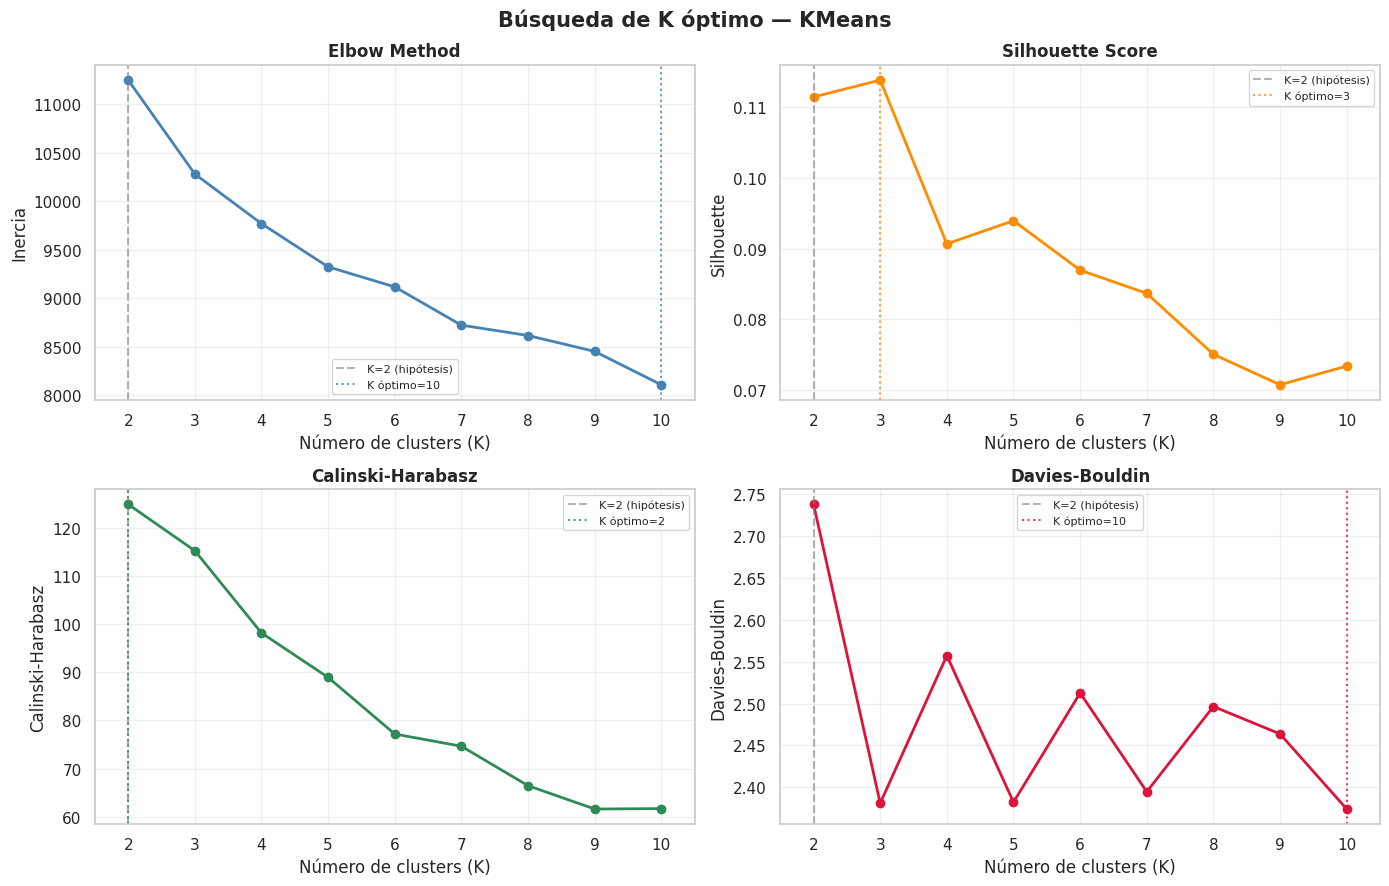

In [ ]:
print("="*60)
print("Búsqueda de K óptimo para KMeans (PCA a atributos numéricos)")
print("="*60)
print("\n")

kmeans_df1 = search_optimal_k(X_pipe1)

Búsqueda de K óptimo para KMeans (PCA global)




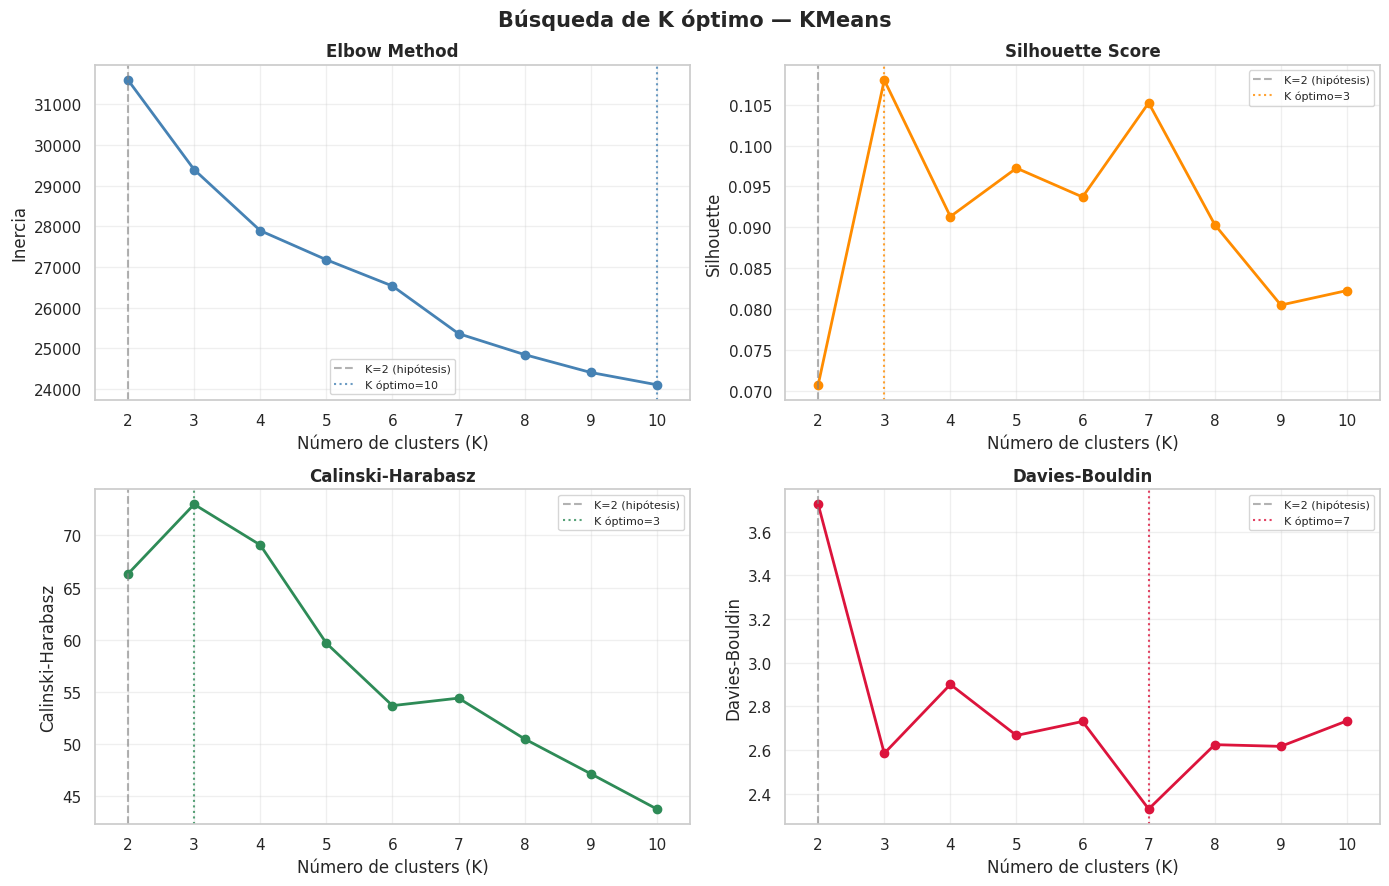

In [ ]:
print("="*60)
print("Búsqueda de K óptimo para KMeans (PCA global)")
print("="*60)
print("\n")

kmeans_df2 = search_optimal_k(X_pipe2)

Búsqueda de hiperparámetros para DBSCAN (PCA a numéricas)




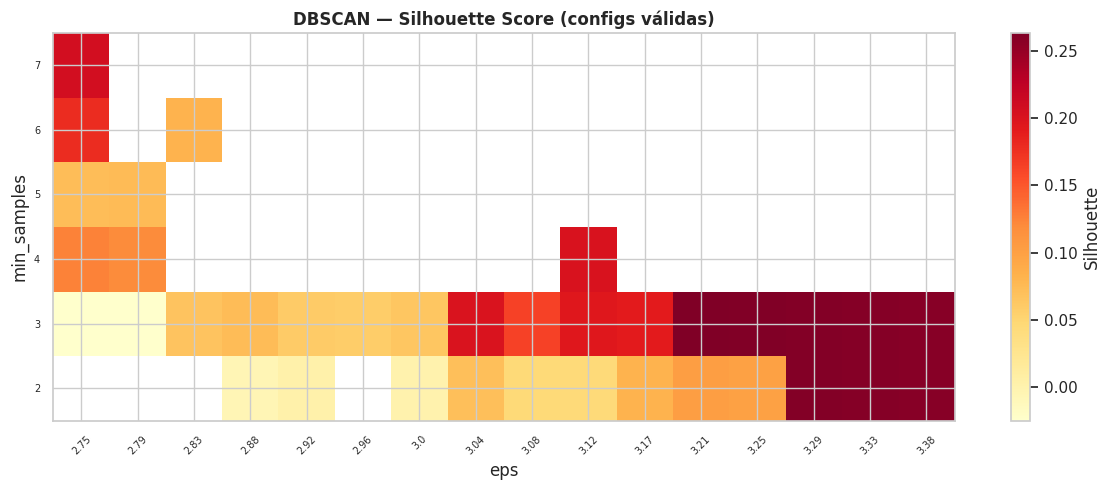


Mejor configuración DBSCAN (por Silhouette):
eps                  3.2100
min_samples          3.0000
n_clusters           2.0000
pct_noise            0.0370
Silhouette           0.2632
Calinski-Harabasz    7.1600
Davies-Bouldin       0.9732


In [ ]:
print("="*60)
print("Búsqueda de hiperparámetros para DBSCAN (PCA a numéricas)")
print("="*60)
print("\n")

r1 = 3.25
eps = 0.5

best_db1, dbscan_df1 = search_dbscan_params(X_pipe1, min_samples_range=range(2, 15), eps_range=np.round(np.linspace(r1-eps, r1+eps,25), 2))

Búsqueda de hiperparámetros para DBSCAN (PCA general)




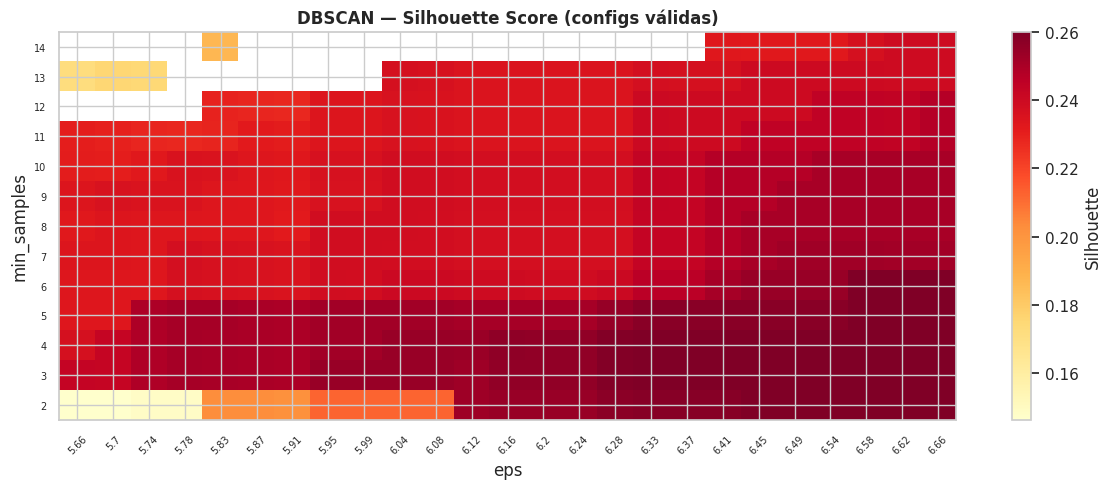


Mejor configuración DBSCAN (por Silhouette):
eps                   6.3300
min_samples           3.0000
n_clusters            5.0000
pct_noise             0.0100
Silhouette            0.2600
Calinski-Harabasz    28.6200
Davies-Bouldin        1.1418


In [ ]:
print("="*60)
print("Búsqueda de hiperparámetros para DBSCAN (PCA general)")
print("="*60)
print("\n")

#r2 = np.sqrt(X_pipe2.shape[1]).round(2)
r2 = 6.16
eps = 0.5

best_db2, dbscan_df2 = search_dbscan_params(X_pipe2, min_samples_range=range(2, 15), eps_range=np.round(np.linspace(r2-eps, r2+eps,25), 2))

#### 3.3.3 Ajuste final de hiperparámtros

In [ ]:
# KMeans — se prueba K=2 (hipótesis) y K óptimo por silhouette
K_HIPOTESIS = 2
K_OPTIMO_P1 = int(kmeans_df1['Silhouette'].idxmax())
K_OPTIMO_P2 = int(kmeans_df2['Silhouette'].idxmax())

km_p1_k2    = KMeans(n_clusters=K_HIPOTESIS, random_state=SEED, n_init='auto').fit(X_pipe1)
km_p1_kopt  = KMeans(n_clusters=K_OPTIMO_P1, random_state=SEED, n_init='auto').fit(X_pipe1)
km_p2_k2    = KMeans(n_clusters=K_HIPOTESIS, random_state=SEED, n_init='auto').fit(X_pipe2)
km_p2_kopt  = KMeans(n_clusters=K_OPTIMO_P2, random_state=SEED, n_init='auto').fit(X_pipe2)

# DBSCAN con mejores parámetros encontrados
eps_p1, ms_p1 = (best_db1['eps'], int(best_db1['min_samples'])) if best_db1 is not None else (0.5, 5)
eps_p2, ms_p2 = (best_db2['eps'], int(best_db2['min_samples'])) if best_db2 is not None else (0.5, 5)

db_p1 = DBSCAN(eps=eps_p1, min_samples=ms_p1).fit(X_pipe1)
db_p2 = DBSCAN(eps=eps_p2, min_samples=ms_p2).fit(X_pipe2)

#### 3.3.4 Evaluación comparativa


##### Interpretación de métricas internas

$$
\begin{array}{lcc}
\textbf{Métrica} & \textbf{Rango} & \textbf{Interpretación} \\
\hline
\text{Silhouette} & [-1, 1] & \text{Mayor es mejor} \\
\text{Calinski-Harabasz} & [0, \infty) & \text{Mayor es mejor} \\
\text{Davies-Bouldin} & [0, \infty) & \text{Menor es mejor}
\end{array}
$$

##### Interpretación de métricas externas (vs etiqueta real)

$$
\begin{array}{lcc}
\textbf{Métrica} & \textbf{Rango} & \textbf{Interpretación} \\
\hline
\text{ARI} & [-1, 1] & \text{Cercano a 1: clusters alineados con bueno/malo} \\
\text{NMI} & [0, 1] & \text{Cercano a 1: alta información mutua}
\end{array}
$$

In [ ]:
print("\n" + "=" * 60)
print("Evaluando modelos...")

experimentos_eval = [
    (f'KMeans K={K_HIPOTESIS} (hip)| Pipeline 1',  km_p1_k2.labels_,   X_pipe1),
    (f'KMeans K={K_OPTIMO_P1} | Pipeline 1',  km_p1_kopt.labels_,  X_pipe1),
    (f'KMeans K={K_HIPOTESIS} (hip)| Pipeline 2',  km_p2_k2.labels_,   X_pipe2),
    (f'KMeans K={K_OPTIMO_P2} | Pipeline 2',  km_p2_kopt.labels_,  X_pipe2),
    (f'DBSCAN eps={eps_p1} | Pipeline 1',      db_p1.labels_,       X_pipe1),
    (f'DBSCAN eps={eps_p2} | Pipeline 2',      db_p2.labels_,       X_pipe2),
]

y_1d = y['class'].replace({2:1, 1:0})

metricas_finales = [
    model_evaluation(nombre, labels, X_tr, y_1d)
    for nombre, labels, X_tr in experimentos_eval
]

df_resultados = pd.DataFrame(metricas_finales).set_index('Modelo')

print("=" * 80)
print("\nTABLA COMPARATIVA DE MODELOS")
print("=" * 80)
print(df_resultados.to_string())


Evaluando modelos...

TABLA COMPARATIVA DE MODELOS
                              N Clusters  N Ruido  Silhouette  Calinski-Harabasz  Davies-Bouldin     ARI     NMI
Modelo                                                                                                          
KMeans K=2 (hip)| Pipeline 1           2        0      0.1114             124.81          2.7377 -0.0053  0.0034
KMeans K=3 | Pipeline 1                3        0      0.1138             115.19          2.3811  0.0278  0.0236
KMeans K=2 (hip)| Pipeline 2           2        0      0.0707              66.32          3.7245  0.0077  0.0029
KMeans K=3 | Pipeline 2                3        0      0.1080              72.98          2.5852  0.0685  0.0162
DBSCAN eps=3.21 | Pipeline 1           2       37      0.2632               7.16          0.9732  0.0005  0.0000
DBSCAN eps=6.33 | Pipeline 2           5       10      0.2600              28.62          1.1418  0.0076  0.0020


Los modelos KMeans presentan una cohesión interna modesta. El silhouette score ronda 0.10–0.11 en Pipeline 1 y baja a 0.07–0.11 en Pipeline 2, lo que indica que los clusters no están bien separados en el espacio de features. DBSCAN logra los mejores valores internos (silhouette ~0.26 en ambos pipelines) y un Davies-Bouldin notablemente menor ($\sim$0.97–1.14 vs $\sim$2.38–3.72 de KMeans), sugiriendo que DBSCAN encuentra agrupaciones más compactas y separadas — aunque a costa de etiquetar entre 10 y 37 observaciones como ruido.
Vale notar que el Pipeline 1 supera consistentemente al Pipeline 2 en Calinski-Harabasz (124 vs 66 para K=2), lo que indica que aplicar PCA solo sobre las variables numéricas preserva mejor la varianza discriminante entre grupos.

Los valores de ARI son prácticamente cero o negativos en todos los experimentos, y el NMI no supera 0.024 en ningún caso. Esto significa que la segmentación no supervisada y la etiqueta de buen/mal cliente son casi independientes entre sí.
En particular, KMeans con K=2 en Pipeline 1 obtiene ARI = −0.005, lo que descarta que existan dos grupos naturales en los datos que correspondan a los perfiles de riesgo. DBSCAN, pese a sus mejores métricas internas, tiene ARI ≈ 0 (0.0005), confirmando que las agrupaciones densas que detecta tampoco se alinean con la variable objetivo.

Por lo tanto, *ningún modelos captura la estructura binaria del riesgo crediticio.*


Generando visualizaciones 2D...


/tmp/ipykernel_231/1209796254.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_cl = plt.cm.get_cmap('tab10', len(unique_labels))
/tmp/ipykernel_231/1209796254.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_cl = plt.cm.get_cmap('tab10', len(unique_labels))
/tmp/ipykernel_231/1209796254.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_cl = plt.cm.get_cmap('tab10', len(unique_labels))
/tmp/ipykernel_231/1209796254.py:22: MatplotlibDepre

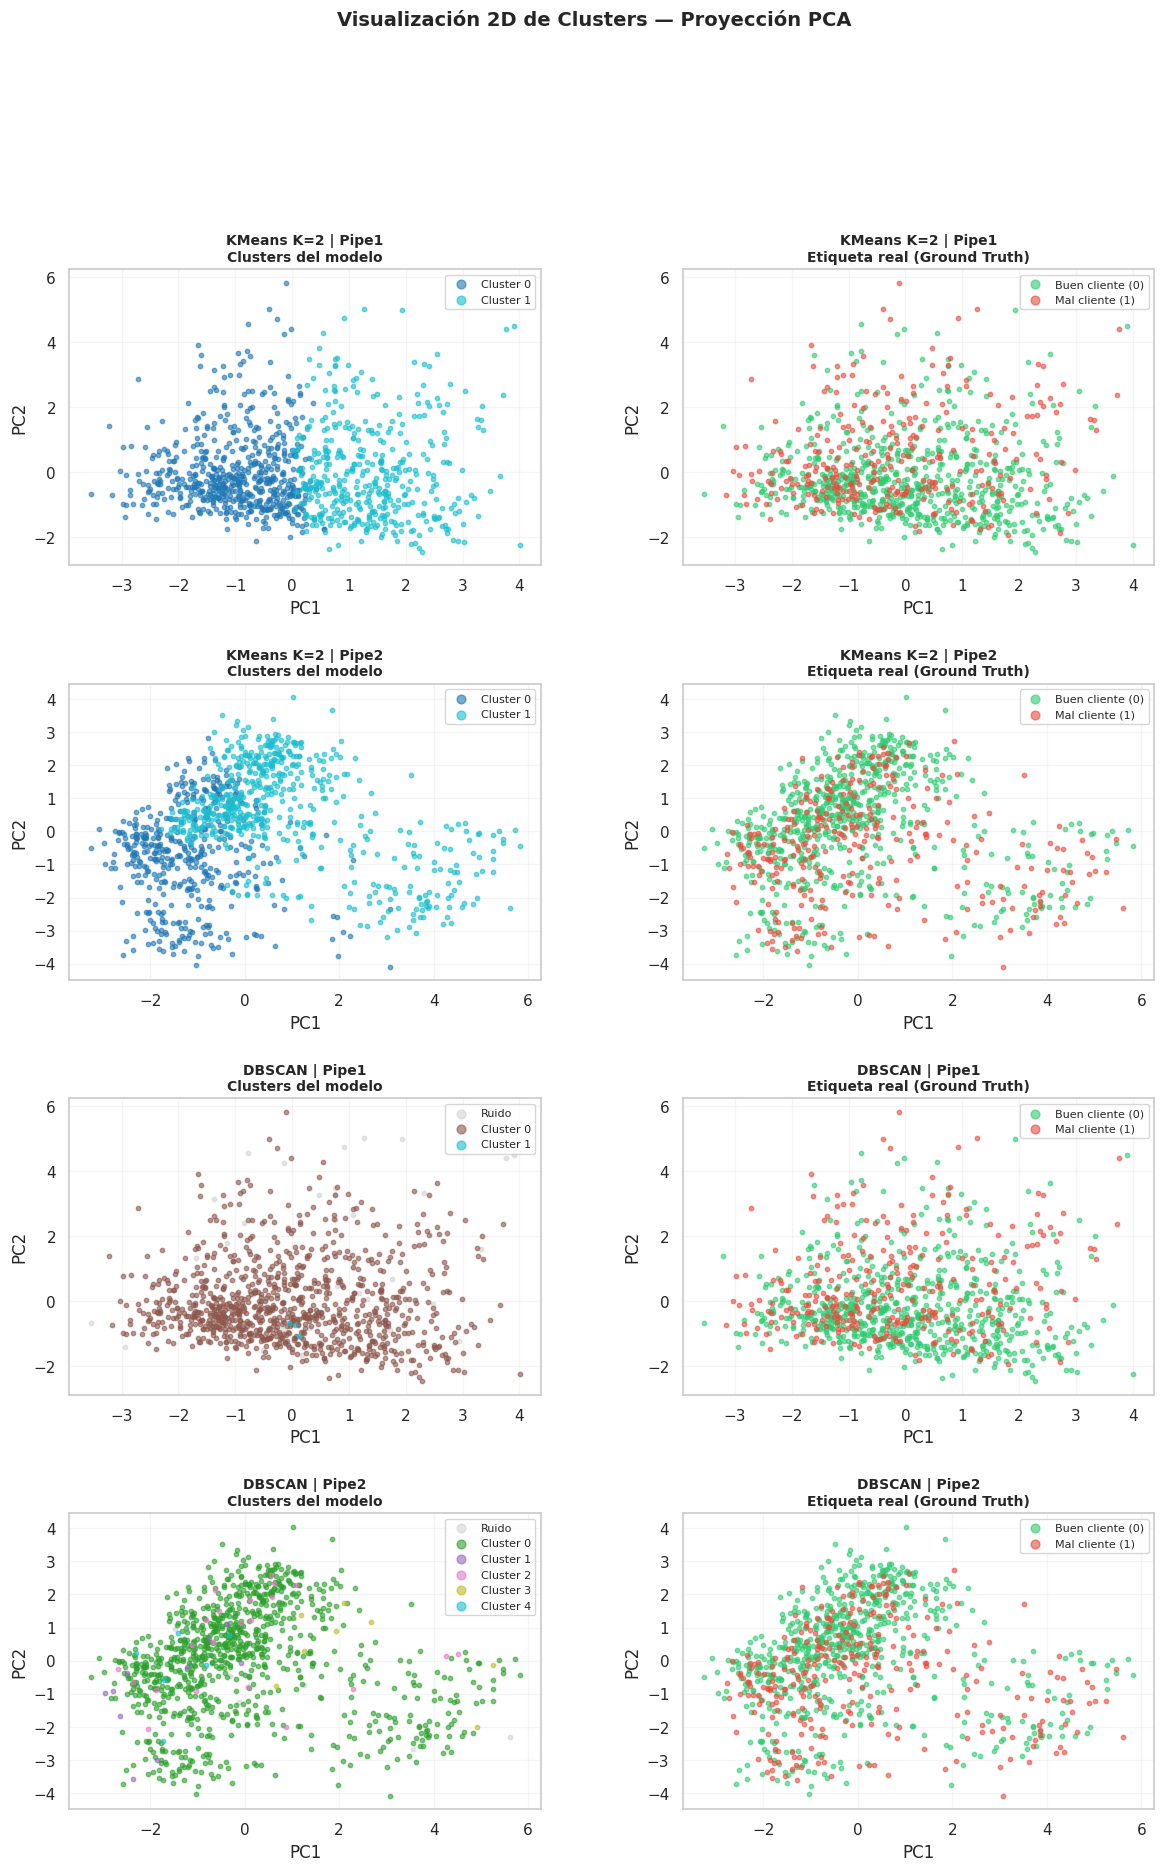

In [ ]:
print("\n" + "=" * 60)
print("Generando visualizaciones 2D...")

experimentos_vis = [
  (f'KMeans K={K_HIPOTESIS} | Pipe1', X_pipe1, km_p1_k2.labels_),
  (f'KMeans K={K_HIPOTESIS} | Pipe2', X_pipe2, km_p2_k2.labels_),
  (f'DBSCAN | Pipe1', X_pipe1, db_p1.labels_),
  (f'DBSCAN | Pipe2', X_pipe2, db_p2.labels_),
]

clusters_visualization_2d(experimentos_vis, y_true=y.replace({2:1, 1:0})['class'])

> Como se puede observar en los gráficos anteriores. Los datos no representan una estructura de clusters que refleje la distinción entre buenos y malos clientes.

### 3.4 Modelos supervisados

#### 3.4.1 Configuración

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold

from classification_settings import (
    build_classification_pipelines,
    run_grid_search,
    run_cross_validation,
    threshold_evaluation,
    plot_costo_umbral,
    plot_umbral_recall,
    plot_roc_pr,
    plot_confusion_matrices
)


# Construir pipelines de clasificación
logistic_pipe1, logistic_pipe2, rforest_pipe1, rforest_pipe2 = build_classification_pipelines()

y_new = y.replace({2: 1, 1: 0})['class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y_new, test_size=0.25, stratify=y_new, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

#### 3.4.2 Busqueda de hiperparámetros para Random Forest

In [ ]:
grid_rf1, grid_rf2 = run_grid_search(rforest_pipe1, rforest_pipe2, X_train, y_train, cv)

GridSearchCV — Random Forest (scoring=recall, CV=StratifiedKFold)

[Pipeline 1 — PCA numérico]
Fitting 5 folds for each of 63 candidates, totalling 315 fits
  Mejores parámetros : {'rforest__criterion': 'entropy', 'rforest__max_depth': 15, 'rforest__n_estimators': 100}
  Mejor Recall (CV)  : 0.3200

[Pipeline 2 — PCA general]
Fitting 5 folds for each of 63 candidates, totalling 315 fits
  Mejores parámetros : {'rforest__criterion': 'gini', 'rforest__max_depth': 10, 'rforest__n_estimators': 100}
  Mejor Recall (CV)  : 0.2356


#### 3.4.3 Validación cruzada

In [ ]:
pipelines_cv = [
    ('Logistic | Pipe1', logistic_pipe1),
    ('Logistic | Pipe2', logistic_pipe2),
    ('RF best  | Pipe1', grid_rf1.best_estimator_),
    ('RF best  | Pipe2', grid_rf2.best_estimator_),
]

df_cv = run_cross_validation(pipelines_cv, X_train, y_train, cv)


Cross-Validation sobre X_train (5 folds estratificados)

RESULTADOS CROSS-VALIDATION (media sobre 5 folds)
                  Recall  Precision      F1  ROC-AUC  Recall_std
Modelo                                                          
Logistic | Pipe1  0.3244     0.5400  0.3993   0.7302      0.1048
Logistic | Pipe2  0.3244     0.5482  0.4017   0.7219      0.0906
RF best  | Pipe1  0.3200     0.6365  0.4204   0.7621      0.0917
RF best  | Pipe2  0.2356     0.5819  0.3344   0.6842      0.0499

Nota: Recall_std indica estabilidad — valores altos sugieren sensibilidad al fold.


#### 3.4.4 Evaluando umbral de decisión

Para evaluar el umbral de decisión se evaluará sobre veinte valores equiespaciados entre 0.15 y 0.75. Para ello, se analizará el desempeño de los modelos con las métricas recall, Precision, F1, Accuracy y ROC-AUC con los datos de prueba y las predicciones ajustadas según el umbral de decisión

In [ ]:
print("\n" + "=" * 60)
print("Evaluación por umbral de decisión — X_test")

final_models = [
    ('Logistic | Pipe1', logistic_pipe1.fit(X_train, y_train)),
    ('Logistic | Pipe2', logistic_pipe2.fit(X_train, y_train)),
    ('RF best  | Pipe1', grid_rf1.best_estimator_),
    ('RF best  | Pipe2', grid_rf2.best_estimator_),
]

thresholds = np.linspace(0.15, 0.75, 20) # umbral de decisión

df_umbrales = pd.concat([
    threshold_evaluation(model, name, X_test, y_test, thresholds)
    for name, model  in final_models
], ignore_index=True)

print("\nMÉTRICAS POR UMBRAL (clase 1 = mal cliente)")
print(df_umbrales.to_string(index=False))





Evaluación por umbral de decisión — X_test

MÉTRICAS POR UMBRAL (clase 1 = mal cliente)
          Modelo   Umbral  Recall  Precision     F1  Accuracy  ROC-AUC
Logistic | Pipe1 0.150000  0.9467     0.3989 0.5613     0.556   0.7903
Logistic | Pipe1 0.181579  0.9467     0.4356 0.5966     0.616   0.7903
Logistic | Pipe1 0.213158  0.8800     0.4615 0.6055     0.656   0.7903
Logistic | Pipe1 0.244737  0.7867     0.4758 0.5930     0.676   0.7903
Logistic | Pipe1 0.276316  0.7200     0.4696 0.5684     0.672   0.7903
Logistic | Pipe1 0.307895  0.6533     0.5104 0.5731     0.708   0.7903
Logistic | Pipe1 0.339474  0.5467     0.5616 0.5541     0.736   0.7903
Logistic | Pipe1 0.371053  0.5200     0.5909 0.5532     0.748   0.7903
Logistic | Pipe1 0.402632  0.4667     0.6034 0.5263     0.748   0.7903
Logistic | Pipe1 0.434211  0.4533     0.6667 0.5397     0.768   0.7903
Logistic | Pipe1 0.465789  0.4000     0.6977 0.5085     0.768   0.7903
Logistic | Pipe1 0.497368  0.3600     0.6923 0.4737     0.7

In [ ]:
print("\n" + "=" * 60)
print("Umbral óptimo por modelo (criterio: máximo Recall en clase 1)")
print("=" * 60 + '\n')

df_optimos = (
    df_umbrales
    .sort_values('Recall', ascending=False)
    .groupby('Modelo', sort=False)
    .first()
    .reset_index()
    [['Modelo', 'Umbral', 'Recall', 'Precision','Accuracy', 'F1', 'ROC-AUC']]
)
print(df_optimos.to_string(index=False))


Umbral óptimo por modelo (criterio: máximo Recall en clase 1)

          Modelo  Umbral  Recall  Precision  Accuracy     F1  ROC-AUC
Logistic | Pipe1    0.15  0.9467     0.3989     0.556 0.5613   0.7903
RF best  | Pipe2    0.15  0.9333     0.3590     0.480 0.5185   0.7154
Logistic | Pipe2    0.15  0.9333     0.3955     0.552 0.5556   0.7765
RF best  | Pipe1    0.15  0.9067     0.3560     0.480 0.5113   0.7728


> Al buscar minimizar los falsos positivos de la clase 1 (malos clientes) es esperable obtener valores de Recall altos, sacrificando precisión.

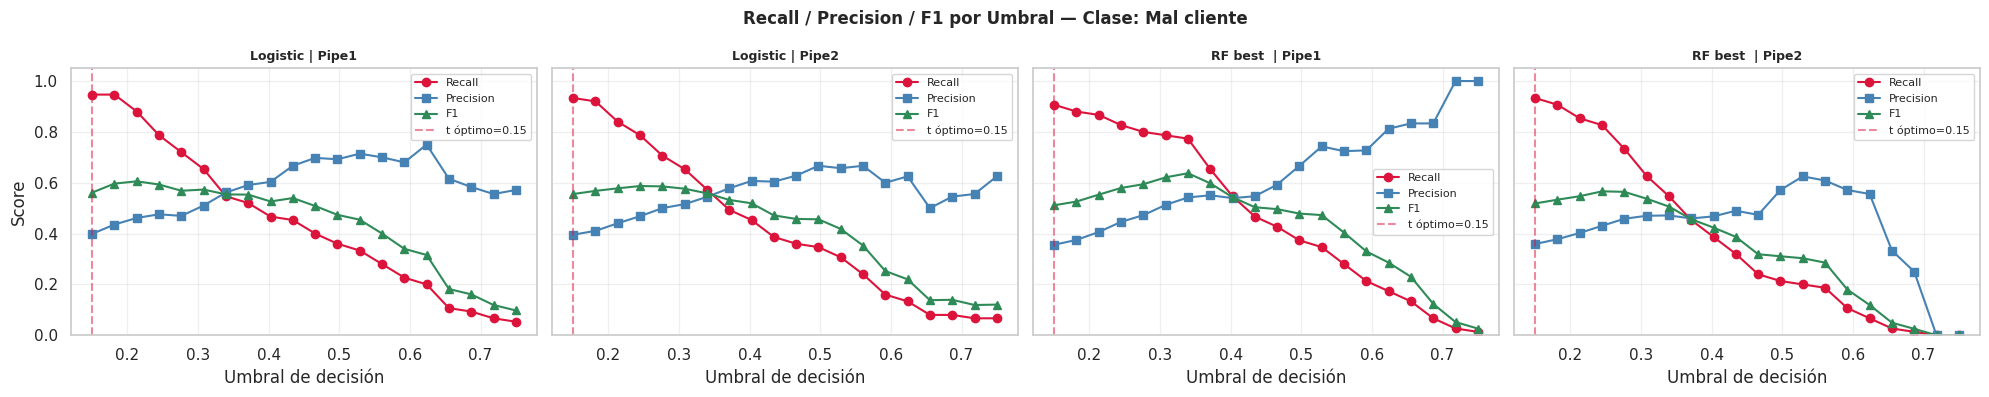

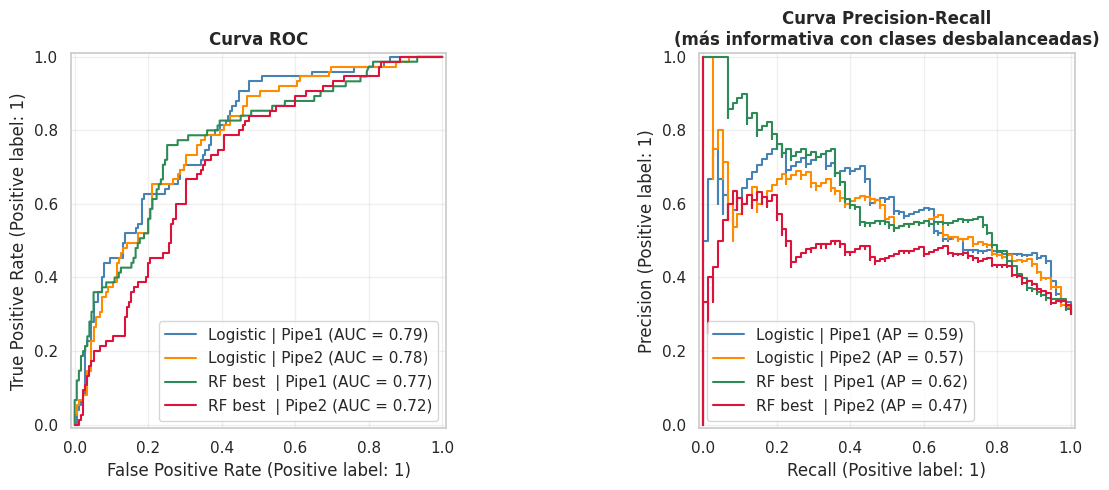

In [ ]:
nombres_modelos = [n for n, _ in final_models]
plot_umbral_recall(df_thresholds, nombres_modelos)
print()
plot_roc_pr(final_models, X_test, y_test)


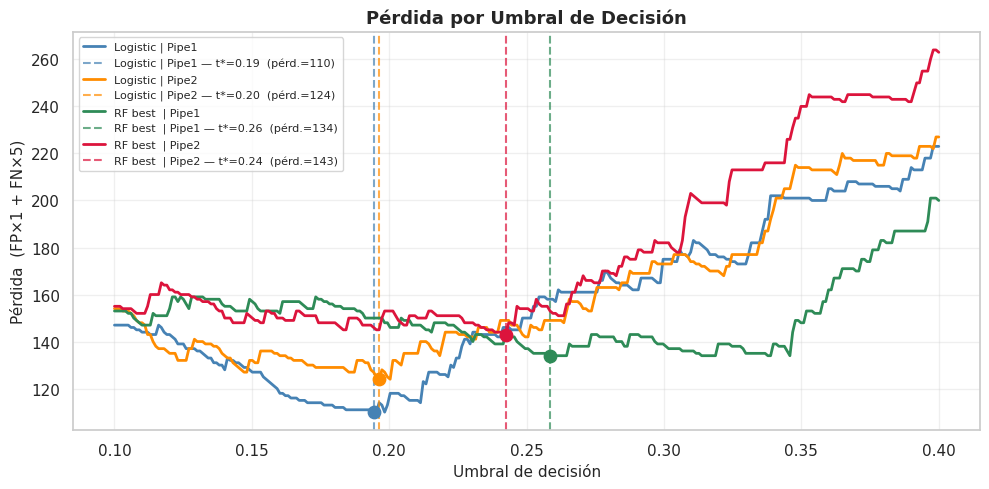


UMBRAL ÓPTIMO POR COSTO (minimiza pérdida total)
   Función de pérdida: FP × 1  +  FN × 5
   FP = buenos → malos  |  FN = malos → buenos

          Modelo  Umbral  FP  FN  Perdida
Logistic | Pipe1  0.1943  90   4      110
Logistic | Pipe2  0.1963  89   7      124
RF best  | Pipe1  0.2585  69  13      134
RF best  | Pipe2  0.2425  83  12      143


In [ ]:
# Pérdida = FP × cost_fp  +  FN × cost_fn
# FP: buenos clasificados como malos  → costo 1  (operación innecesaria)
# FN: malos clasificados como buenos  → costo 5  (riesgo crediticio real)

from numpy import linspace

df_costos = plot_costo_umbral(models=final_models,X_test=X_test,y_test=y_test,
                              thresholds = linspace(0.1, 0.4, 300) ,
                              cost_fp=1,cost_fn=5)


#### 3.4.5 Selección de umbral de decisión y modelo

Tras analizar la pérdida respecto al umbral de decisión y el rendimiento de las distintas métricas al variar el valor de umbral
podemos notar lo siguiente:

1. Los dos modelos con PCA en numéricas logran mimizar la pérdida respecto al mismo modelo pero con un preprocesamiento diferente.
2. La regresión logística (pca en numéricas) logra minizar la pérdida en 111 con un umbral de 0.1873
3. Al revisar el gráfico *Recall / Precision / F1 por Umbral — Clase: Mal cliente* se observa que la regresión logística es más sensible al umbral de decisión, pues  el valor de recall decae a partir del umbral 0.2
4. Al revisar los gráficos *Recall / Precision / F1 por Umbral — Clase: Mal cliente* y *Curva Presicion-Recall* notamos que el modelo Random Forest tiene un mejor rendimiento para las métricas *precision* y *recall*, logrando una precisión promedio de 0.62. Además, se observa una mejor estabilidad de los valores del umbral entre 0.2 y 0.3 para las métricas mencionadas anteriormente.



Por los punto anteriores se ha decidio que el modelo que se seleccionara para futuras predicciones es **Random Forest** con PCA solo en los atributos numéricos y el umbral de decisión por utilizar es $\alpha = 0.25$




In [ ]:
idx = np.argmin(df_costos.loc[df_costos['Modelo'] == 'RF best  | Pipe1'].Perdida)
threshold_selected = df_costos.loc[df_costos['Modelo'] == 'RF best  | Pipe1'].iloc[idx].Umbral
model_selected= grid_rf1.best_estimator_

In [ ]:
model_selected

Pipeline(steps=[('data_transfomer_pcanum',
                 Pipeline(steps=[('preprocessor',
                                  ColumnTransformer(transformers=[('num',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='median')),
                                                                                   ('scaler',
                                                                                    StandardScaler()),
                                                                                   ('pca',
                                                                                    PCA(n_components=0.95))]),
                                                                   ['Attribute2',
                                                                    'Attribute5',
                                                                    'Attribute8',
                                                                    'Attribute11',
                                                                    'Attribute13',
                                                                    'Attribute16']),
                                                                  ('onehot',
                                                                   Pipeline(steps=[('imp...
                                                                                                                'A11',
                                                                                                                'A12',
                                                                                                                'A13'],
                                                                                                               ['A65',
                                                                                                                'A61',
                                                                                                                'A62',
                                                                                                                'A63',
                                                                                                                'A64'],
                                                                                                               ['A71',
                                                                                                                'A72',
                                                                                                                'A73',
                                                                                                                'A74',
                                                                                                                'A75'],
                                                                                                               ['A171',
                                                                                                                'A172',
                                                                                                                'A173',
                                                                                                                'A174']],
                                                                                                   handle_unknown='use_encoded_value',
                                                                                                   unknown_value=-1))]),
                                                                   ['Attribute1',
                                                                    'Attribute6',
                                                                    'Attribute7',
                    

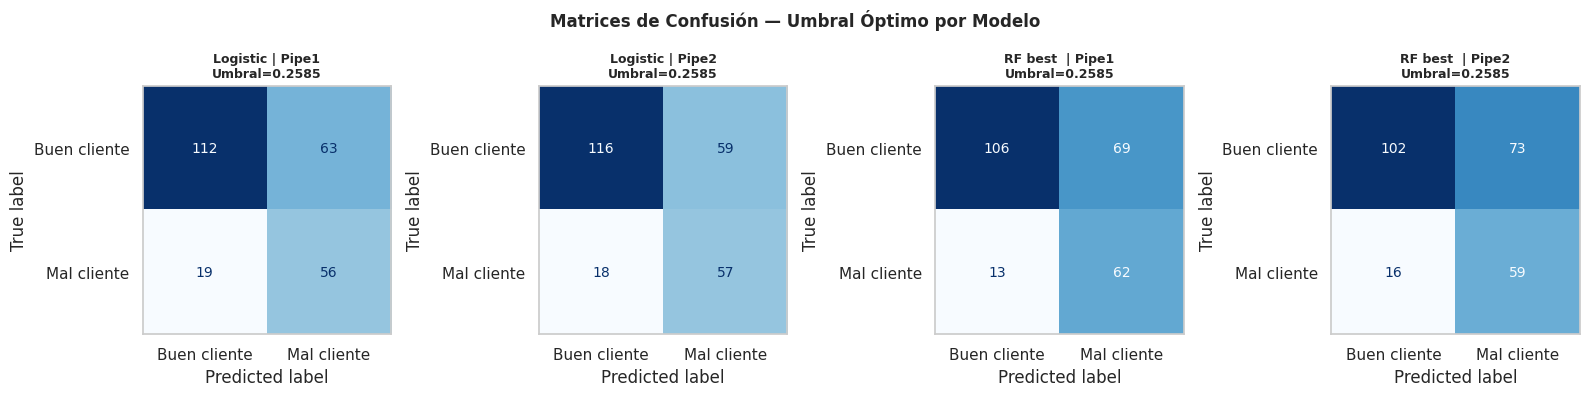

In [ ]:
threshold = 0.2585 # threshold_selected
plot_confusion_matrices(final_models, threshold, X_test, y_test)

In [ ]:
from sklearn.metrics import classification_report

print("\n" + "=" * 60)
print("\t\tClassification Report")
print("=" * 60 + "\n")

proba = model_selected.predict_proba(X_test)[:, 1]
preds = (proba >= threshold_selected).astype(int)
print(f"{'─' * 50}")
print(f"  Random Forest (PCA numéricas) --- (umbral={threshold_selected})")
print(classification_report(y_test, preds,
                              target_names=['Buen cliente', 'Mal cliente'],
                              zero_division=0))



		Classification Report

──────────────────────────────────────────────────
  Random Forest (PCA numéricas) --- (umbral=0.2585)
              precision    recall  f1-score   support

Buen cliente       0.89      0.61      0.72       175
 Mal cliente       0.47      0.83      0.60        75

    accuracy                           0.67       250
   macro avg       0.68      0.72      0.66       250
weighted avg       0.77      0.67      0.69       250



## 4. Conclusiones

### 4.1 Modelos no supervisados  $-$ Segmentación de clientes bancarios


El objetivo principal de usar un modelos de segmentación fue para identificar si existen perfiles naturales que distingan a los clientes buenos de los malos, sin utilizar la etiqueta de riesgo como guía. Se evaluaron dos formas distintas preparar los datos y se constrastaron los grupos resultantes como la etiqueta real de cada cliente.

Tras analizar los resultados obtenidos observamos que la segmentación no logró separar a los clientes buenos de los malos. En todos los escenarios probados, los grupos generados por los modelos mezclan ambos perfiles de riesgo de manera casi aleatoria ya que los indicadores *ARI* y *NMI* son casi nulos en todos los casos.

Por los que, **las características disponibles de los clientes no forman agrupaciones naturales que coincidan con la etiqueta dada sobre su comportamiento crediticio**. Esto no invalida el análisis hecho, sino que es una hallazgo relevante para el equipo de riesgo, ya que esto indica que el otorgamiento crediticio no puede simplicarse a perfiles de clientes evidentes, y que la distinción entre *buenos* y *malos* pagadores responde a combinaciones más sutiles de variables.






### 4.2 Modelos Supervisados $-$ Clasificación crediticia

Después de haber realizado la tarea de segmentación con un resultado distinto al esperado, se optó por entrenar y comparar cuatro configuraciones de modelos supervisados, *Regresión logística* y *Random Forest*, cada uno sobre dos esquemas de preprocesamiento distintos; con el objetivo de clasificar a los clientes buenos y malos pagadores. Para cada modelo se evaluaros distintos tipos de umbrales de decisión y se seleccionó el modelo final considerando tanto la capacidad discriminante general como la pérdida operativa asociada a cada tipo de error.

#### **Selección del modelo**:

El modelo seleccionado es *Random Forest con PCA en atributos numéricos*, operando con un umbral de decisión de 0.2585. Esta configuración fue elegida por las siguientes razones:

1. Es el modelo con mayor capaciodad discrimante entre los otros evaluados, con un *Average Precision de 0.62* en la curva Precision-Recall, el caul es un valor suficientemente bueno aún cuando los clientes buenos son más frecuentes que los malos.
2. Con el umbral seleccionado el modelos detecta el $83\%$ de los clientes malos, reduciendo al minimo el riesgo de otorgar crédito a clientes que no lo pagarán.
3. Aunque la Regresión Logística sobre el primer pipeline registra la pérdida absoluta más baja (110 vs 134 del RF), la diferencia es de 24 unidades. Si embargo, su capacidad predictiva decaia al tener umbrales de decisión menos restrictivas (entre 2.0 a 3.0)

##### **¿Qué tan bien predice el modelo?**

El modelo seleccionado opera con una exactitud global del $67\%$, lo cual es esperado y acepatable debido al desbalance entre las categorias y que se priorizará la detección de los clientes malos sobre la exactitud general.

- Para los clientes malos, el modelo logra un recall de $83\%$ con una precisión del $47\%$. En términos prácticos, de cada 10 clientes marcados como malos, aproximadamente 5 son efectivamente malos y 5 son buenos rechazados incorrectamente. Este es el costo operativo de la estrategia conservadora adoptada.
- Para los buenos clientes, el modelo identifica correctamente al 61% con una precisión del 89%, lo que indica que cuando el modelo aprueba a un cliente, hay alta confianza en que efectivamente es buen pagador.

#### Implicaciones para el equipo de riesgo.


El umbral de 0.2585 representa una postura conservadora frente al riesgo: el modelo prefriere rechazar clientes buenos antes que aprobar a clientes malos. Si bien esto es consistente con una política de otorgamiento prudente, aproximadamente 4 de cada 10 clientes buenos serían rechazados bajo este criterio.

Entonces, se recomendaría al equipo de riesgo a evaluar periódicamente si la relación de costos asumida (1 a 5) sigue siendo representativa de la pérdida real por cada tipo de error, pues un cambio en esa proporción podría justificar ajustar el umbral en un rango de 2.6 a 3.0 para recuperar parte de la cartera de los buenos clientes sin comprometer significativamente la detección de malos.